# 06 · Bridge to neural networks

Notebooks 01–05 solved the whole chain – sweeps, sensitivity, calibration,
surrogates, design optimisation – without a single neural network. That is
deliberate and worth stating plainly: **for a physics model with a handful of
parameters and scalar KPIs, classical tools are the efficient choice.** Least
squares calibrated eight parameters in 81 runs; a Gaussian process learned a KPI
from 32.

Neural networks enter where those tools run out:

| Situation | Why classical tools struggle | NN role |
|---|---|---|
| Surrogate for **whole curves or fields** (hundreds of outputs) | one GP per output does not scale | one network, many outputs |
| **Thousands to millions** of training runs or measurements | GP training cost grows with N³ | training cost grows linearly |
| Calibration or inference needed **many times or in real time** | every calibration re-runs the model | train once, evaluate in microseconds, gradients for free |
| Systematic **model–reality gap** with no obvious physical fix | parameters cannot absorb it (notebook 03, data set B) | learn the residual: hybrid model |
| Time-domain behaviour with memory (nonlinear, hysteretic) | KPIs lose the dynamics | sequence models, neural ODEs |

This notebook does the first four on the driveline example, with PyTorch.

## 1 · A neural network in five sentences

A multilayer perceptron (MLP) is a chain of layers
$\mathbf{h}_{k+1} = \sigma(\mathbf{W}_k\mathbf{h}_k + \mathbf{b}_k)$: a weighted sum followed by a smooth
nonlinearity. The weights are found by minimising the mean squared error on
training data with a gradient method (Adam), in small random batches; the
gradients come from automatic differentiation. One pass through the data is an
*epoch*. A part of the data is held back as *validation* set to see when the
network starts memorising instead of generalising. Inputs and outputs must be
scaled to order one, or training fails – the same lesson as parameter scaling
in notebook 01.

(The project guide `ML_intro_guide.md` and its script `00_nn_basics.py` cover
these basics in more detail.)

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.optimize import least_squares
from scipy.stats import qmc

import driveline as dl
import plotstyle
C = plotstyle.use()
torch.manual_seed(0)
np.set_printoptions(precision=3, suppress=True)
D = dl.N_PAR
rms = lambda a: float(np.sqrt(np.mean(np.square(a))))

## 2 · A surrogate for the whole run-up

Target: a network that maps the 8 parameters to **all 810 log-amplitudes**
(2 channels × 5 orders × 81 speeds) of the linear model – a drop-in replacement
for `dl.simulate`.

### 2.1 Training data

The model is cheap, so data are plentiful: 8192 Sobol samples for training and
validation, 1024 independent ones for testing.

In [2]:
def make_data(n, seed):
    U = qmc.Sobol(d=D, seed=seed).random(n)
    Y = np.array([np.log(dl.simulate(dl.from_unit(u)) + 0.05).ravel() for u in U])
    return U, Y


t0 = time.perf_counter()
U_all, Y_all = make_data(8192, seed=1)
U_test, Y_test = make_data(1024, seed=2)
print(f"{len(U_all) + len(U_test)} model runs in {time.perf_counter() - t0:.1f} s;  output dimension {Y_all.shape[1]}")

9216 model runs in 3.2 s;  output dimension 810


### 2.2 Compressing the output

Neighbouring speed points are highly correlated, so the 810 outputs do not
carry 810 independent pieces of information. **Principal component analysis**
(PCA, here via the SVD) finds an orthogonal basis of "typical curve shapes",
ordered by how much variance they explain. The network then only has to predict
the first few dozen coefficients; multiplying by the basis restores the curves.

How many components? Look at the reconstruction error on the test set.

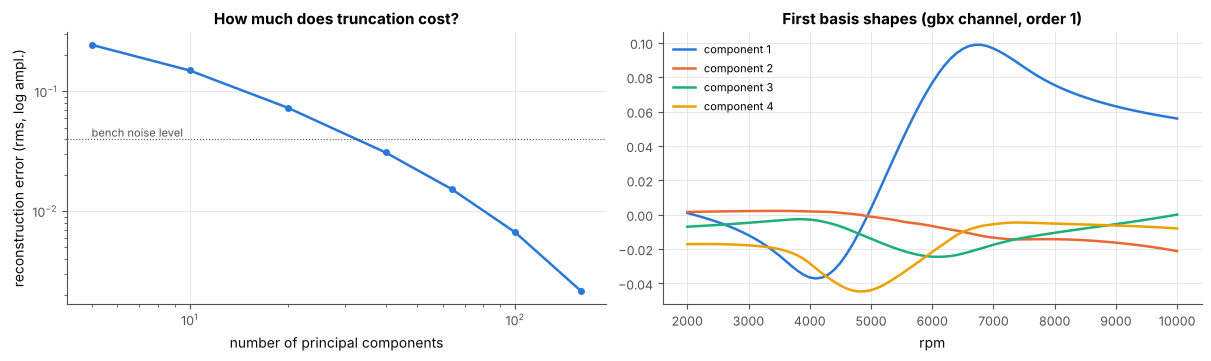

In [3]:
y_mean = Y_all.mean(axis=0)
_, sing, Vt = np.linalg.svd(Y_all - y_mean, full_matrices=False)
n_list = [5, 10, 20, 40, 64, 100, 160]
rec = [rms((Y_test - y_mean) - (Y_test - y_mean) @ Vt[:n].T @ Vt[:n]) for n in n_list]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].loglog(n_list, rec, "o-")
ax[0].axhline(0.04, color=plotstyle.MUTED, lw=0.8, ls=":")
ax[0].text(n_list[0], 0.042, "bench noise level", fontsize=8, color=plotstyle.MUTED)
ax[0].set(xlabel="number of principal components", ylabel="reconstruction error (rms, log ampl.)",
          title="How much does truncation cost?")
i1 = list(dl.ORDERS).index(1.0)
for k in range(4):
    ax[1].plot(dl.RPM, Vt[k].reshape(2, len(dl.ORDERS), -1)[1, i1], label=f"component {k + 1}")
ax[1].set(xlabel="rpm", title="First basis shapes (gbx channel, order 1)")
ax[1].legend(fontsize=8)
plt.show()
N_COMP = 64

The error falls slowly: about 40 components are needed to get below the bench
noise level, and we take 64. The reason is physical. PCA is a *linear* basis; it
is efficient for curves that scale up and down, and inefficient for **features
that move sideways**. A resonance peak that shifts along the rpm axis needs
many fixed shapes to be represented at every position. Lightly damped,
wandering resonances are the hard case for any curve surrogate – worth
remembering before promising a "digital twin" of an NVH model.

### 2.3 Network and training loop

Three hidden layers of 256 units, smooth activation, Adam with a decaying
learning rate. The loop is written out so that nothing is hidden: forward pass,
loss, backward pass, optimiser step.

training: 34 s on CPU, 150336 weights


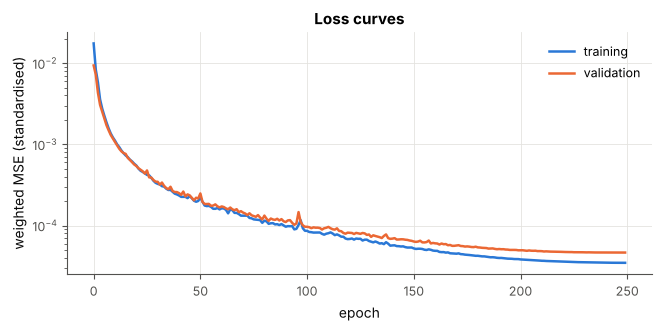

In [4]:
class Scaler:
    """PCA projection + standardisation of the coefficients."""
    def __init__(self, Y, n_comp):
        self.mean = Y.mean(axis=0)
        self.V = np.linalg.svd(Y - self.mean, full_matrices=False)[2][:n_comp]
        Z = (Y - self.mean) @ self.V.T
        self.std = Z.std(axis=0)
        # torch copies for differentiable decoding
        self.V_t = torch.tensor(self.V, dtype=torch.float32)
        self.mean_t = torch.tensor(self.mean, dtype=torch.float32)
        self.std_t = torch.tensor(self.std, dtype=torch.float32)

    def encode(self, Y):
        return ((Y - self.mean) @ self.V.T) / self.std

    def decode_t(self, z):                      # torch: standardised coefficients -> log-amplitudes
        return (z * self.std_t) @ self.V_t + self.mean_t


def make_net(n_out, width=256):
    return nn.Sequential(nn.Linear(D, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(),
                         nn.Linear(width, width), nn.SiLU(), nn.Linear(width, n_out))


def train_surrogate(U, Y, n_comp=N_COMP, epochs=250, batch=128, seed=0):
    torch.manual_seed(seed)
    sc = Scaler(Y, n_comp)
    X = torch.tensor(2 * U - 1, dtype=torch.float32)                 # inputs in [-1, 1]
    T = torch.tensor(sc.encode(Y), dtype=torch.float32)
    weight = torch.tensor(sc.std / sc.std[0], dtype=torch.float32)   # important components count more
    n_val = len(X) // 8
    Xv, Tv, Xt, Tt = X[:n_val], T[:n_val], X[n_val:], T[n_val:]
    net = make_net(n_comp)
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        run = 0.0
        for i in range(0, len(Xt), batch):
            idx = perm[i:i + batch]
            loss = (((net(Xt[idx]) - Tt[idx]) * weight) ** 2).mean()   # forward + loss
            opt.zero_grad()
            loss.backward()                                            # gradients by autodiff
            opt.step()                                                 # update weights
            run += loss.item() * len(idx)
        sched.step()
        with torch.no_grad():
            hist.append((run / len(Xt), (((net(Xv) - Tv) * weight) ** 2).mean().item()))
    return net, sc, np.array(hist)


def predict(net, sc, U):
    with torch.no_grad():
        return sc.decode_t(net(torch.tensor(2 * np.atleast_2d(U) - 1, dtype=torch.float32))).numpy()


t0 = time.perf_counter()
net, sc, hist = train_surrogate(U_all, Y_all)
print(f"training: {time.perf_counter() - t0:.0f} s on CPU, "
      f"{sum(p.numel() for p in net.parameters())} weights")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.semilogy(hist[:, 0], label="training")
ax.semilogy(hist[:, 1], label="validation")
ax.set(xlabel="epoch", ylabel="weighted MSE (standardised)", title="Loss curves")
ax.legend()
plt.show()

Training and validation loss fall together and level off: no sign of
overfitting. A validation curve that turns upward while the training curve
keeps falling would be the cue to stop earlier, shrink the network or add data.

### 2.4 How good is it?

rms log-amplitude error on 1024 unseen parameter sets: median 0.016, 90th percentile 0.034, worst 0.078


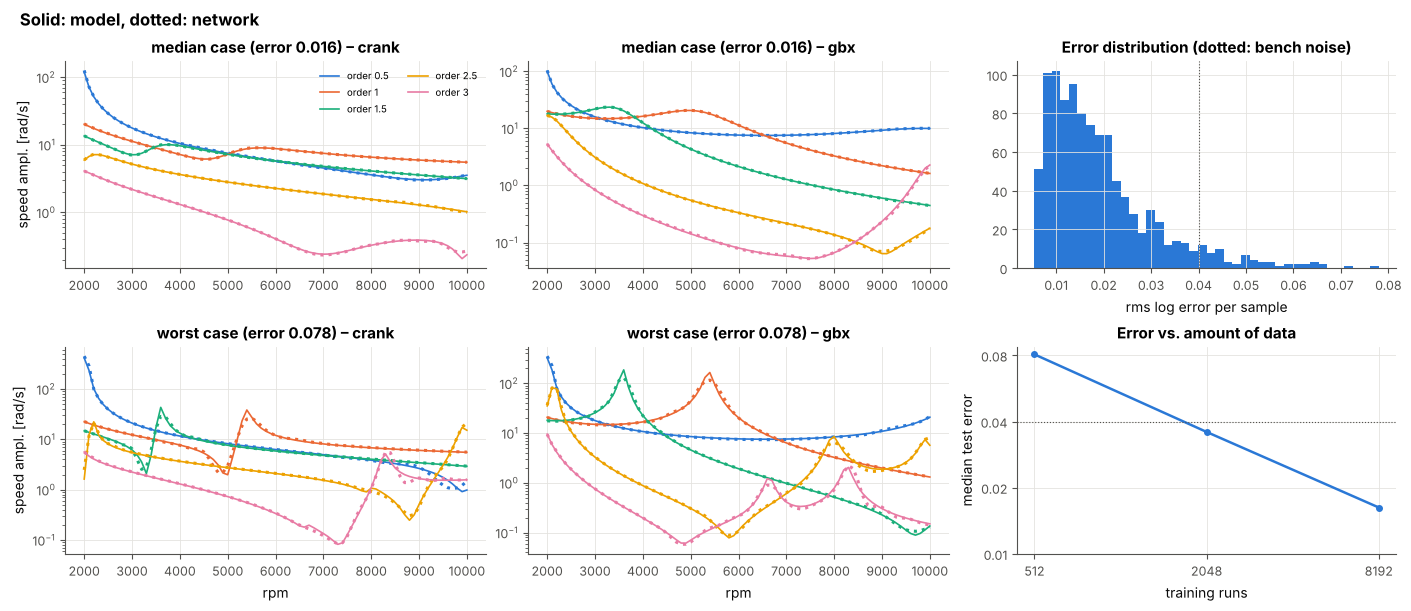

median error by training size: {512: 0.081, 2048: 0.036, 8192: 0.016}


In [5]:
P_test = predict(net, sc, U_test)
err_curve = np.sqrt(np.mean((P_test - Y_test) ** 2, axis=1))       # rms log error per test sample
print(f"rms log-amplitude error on 1024 unseen parameter sets: median {np.median(err_curve):.3f}, "
      f"90th percentile {np.percentile(err_curve, 90):.3f}, worst {err_curve.max():.3f}")

order_ = np.argsort(err_curve)
picks = {"median case": order_[len(order_) // 2], "worst case": order_[-1]}
fig, axes = plt.subplots(2, 3, figsize=(14, 6), width_ratios=[1, 1, 0.9])
for row, (lab, i) in enumerate(picks.items()):
    yt = Y_test[i].reshape(2, len(dl.ORDERS), -1)
    yp = P_test[i].reshape(2, len(dl.ORDERS), -1)
    for ch in range(2):
        a = axes[row, ch]
        for o, n in enumerate(dl.ORDERS):
            a.plot(dl.RPM, np.exp(yt[ch, o]), color=C[o], lw=1.2, label=f"order {n:g}" if (row, ch) == (0, 0) else None)
            a.plot(dl.RPM, np.exp(yp[ch, o]), color=C[o], lw=2.2, ls=":", )
        a.set(yscale="log", title=f"{lab} (error {err_curve[i]:.3f}) – {dl.CHANNELS[ch]}",
              xlabel="rpm" if row else "", ylabel="speed ampl. [rad/s]" if ch == 0 else "")
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 2].hist(err_curve, bins=40, color=C[0])
axes[0, 2].axvline(0.04, color=plotstyle.MUTED, lw=0.8, ls=":")
axes[0, 2].set(xlabel="rms log error per sample", title="Error distribution (dotted: bench noise)")

sizes = [512, 2048, 8192]
med = [np.median(err_curve) if n == 8192 else
       np.median(np.sqrt(np.mean((predict(*train_surrogate(U_all[:n], Y_all[:n])[:2], U_test) - Y_test) ** 2, axis=1)))
       for n in sizes]
axes[1, 2].loglog(sizes, med, "o-")
axes[1, 2].axhline(0.04, color=plotstyle.MUTED, lw=0.8, ls=":")
axes[1, 2].minorticks_off()
axes[1, 2].set(xlabel="training runs", ylabel="median test error", title="Error vs. amount of data",
               xticks=sizes, xticklabels=sizes, yticks=[0.01, 0.02, 0.04, 0.08], yticklabels=["0.01", "0.02", "0.04", "0.08"])
fig.suptitle("Solid: model, dotted: network", x=0.01, ha="left", fontweight="bold")
plt.show()
print("median error by training size:", {n: round(float(m), 3) for n, m in zip(sizes, med)})

With 8192 runs the network reproduces unseen run-ups with a typical error well
below the 4 % bench scatter; the worst cases are the ones with the sharpest
resonances. With 512 runs it is clearly not good enough. **Thousands of runs for
eight inputs** – compare that with the 32 runs the Gaussian process needed for a
smooth scalar KPI in notebook 04. The price of predicting whole curves with
moving resonances is data. If each run took a minute, this surrogate would cost
almost six days of computing, and the right decision would be to reduce the
problem first (fewer parameters after screening, KPIs instead of curves).

### 2.5 What you get in return: speed and gradients

In [6]:
xb = torch.rand(100_000, D) * 2 - 1
t0 = time.perf_counter()
with torch.no_grad():
    sc.decode_t(net(xb))
t_nn = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(200):
    dl.simulate(dl.NOMINAL)
t_model = (time.perf_counter() - t0) / 200
print(f"network: 100 000 run-ups in {t_nn:.2f} s  ({t_nn / 1e5 * 1e6:.1f} µs each);  "
      f"model: {t_model * 1e3:.2f} ms each  →  factor {t_model / (t_nn / 1e5):.0f}")

network: 100 000 run-ups in 0.66 s  (6.6 µs each);  model: 0.25 ms each  →  factor 38


Because the network is a differentiable function, the derivative of the misfit
with respect to the *inputs* (the physical parameters) comes from the same
automatic differentiation that trained it. Calibration becomes gradient descent
on the inputs – and since everything is batched, **64 multi-starts run at once**.

In [7]:
bench = dl.load_bench("A")
target = torch.tensor(np.log(bench["amp"] + 0.05).ravel(), dtype=torch.float32)

torch.manual_seed(1)
raw = torch.randn(64, D).requires_grad_(True)        # unconstrained; tanh maps to the box [-1, 1]
opt = torch.optim.Adam([raw], lr=0.05)
t0 = time.perf_counter()
for it in range(400):
    misfit = ((sc.decode_t(net(torch.tanh(raw))) - target) ** 2).mean(dim=1)     # one value per start
    opt.zero_grad()
    misfit.sum().backward()
    opt.step()
t_cal = time.perf_counter() - t0
with torch.no_grad():
    x_unit = torch.tanh(raw)
    final = ((sc.decode_t(net(x_unit)) - target) ** 2).mean(dim=1).sqrt().numpy()
best = int(final.argmin())
x_nn = dl.from_unit((x_unit[best].numpy() + 1) / 2)

cal = np.load("data/calibration.npz")
print(f"64 calibrations × 400 gradient steps in {t_cal:.1f} s;  "
      f"{np.sum(final < final.min() * 1.05)} of 64 starts reach the best cost")
print(f"cost according to the network {final.min():.4f},  true model at that point {dl.cost(x_nn, bench):.4f}")
print(f"\n{'':10s} {'via network':>12s} {'least squares (nb 03)':>22s} {'truth':>8s}")
for n, a, b, c in zip(dl.NAMES, x_nn / dl.NOMINAL, cal["x_A"] / dl.NOMINAL, cal["x_true"] / dl.NOMINAL):
    print(f"{n:10s} {a:12.3f} {b:22.3f} {c:8.3f}")

count = [0]
def res(l):
    count[0] += 1
    return dl.residuals(np.exp(l), bench)
pol = least_squares(res, np.log(x_nn), bounds=(np.log(dl.LOWER), np.log(dl.UPPER)))
print(f"\npolishing with the real model from the network's answer: {count[0]} runs → cost {rms(pol.fun):.4f}")

64 calibrations × 400 gradient steps in 0.7 s;  63 of 64 starts reach the best cost
cost according to the network 0.0412,  true model at that point 0.0406

            via network  least squares (nb 03)    truth
k_prim            1.234                  1.234    1.250
k_damper          0.820                  0.822    0.820
k_shaft           1.148                  1.151    1.150
k_cush            1.302                  1.307    1.300
c_damper          1.835                  1.855    1.900
c_cush            0.773                  0.759    0.700
J_gbx             1.118                  1.124    1.120
gas_scale         0.939                  0.939    0.940

polishing with the real model from the network's answer: 45 runs → cost 0.0406


The calibration through the network lands on practically the same parameters as
the least-squares fit of notebook 03, in well under a second for 64 starts. A
short polish with the real model removes the remaining surrogate error – always
finish on the real model.

**Is that worth 8192 training runs when least squares needed 81?** For a single
calibration, no. The network pays off when its cost is *amortised*:

* calibrating many units – every engine off the line, every test of a campaign,
  every variant in a family that shares the model structure;
* Bayesian uncertainty by MCMC, which needs 10⁵–10⁶ evaluations;
* robust design (notebook 05) with tens of thousands of evaluations;
* real-time use: on-bench monitoring, model-based control, hardware-in-the-loop.

## 3 · Hybrid modelling: a network for what the physics misses

Back to data set B. The calibrated model left a structured residual
(unmodelled alternator resonance, hysteretic damping). Option 3 from notebook 03:
keep the physics model and train a small network on the **discrepancy**

$$\delta = \ln y^{\text{bench}} - \ln y^{\text{model}}(\hat{\boldsymbol\theta}),\qquad
  \ln y^{\text{hybrid}} = \ln y^{\text{model}}(\hat{\boldsymbol\theta}) + \delta_{NN}(\text{features})$$

The physics carries the bulk and the extrapolation; the network only has to
learn a correction. The decisive question is **which inputs the correction
network gets**. Two candidates:

* **(channel, order, rpm)** – the coordinates of the data table;
* **(channel, frequency)** with $f = \text{order}\times\text{rpm}/60$ – a physical statement:
  "the model error sits in the transfer path, and a transfer path depends on
  frequency, not on which engine order happens to excite it".

We train an ensemble of five small networks for each choice (the spread of the
ensemble is a cheap uncertainty indicator) and test in two ways: on the run-up at
50 % load, and – harder – with order 2.5 removed from the training data.

In [8]:
bench_B, val_B = dl.load_bench("B"), dl.load_bench("B_val")
xB = cal["x_B"]                                                  # parameters calibrated on B in notebook 03
shape = (2, len(dl.ORDERS), len(dl.RPM))
delta_B = -dl.residuals(xB, bench_B)                             # bench − model, log units
delta_V = -dl.residuals(xB, val_B)
ch, od, rp = (a.ravel() for a in np.meshgrid(np.arange(2), dl.ORDERS, dl.RPM, indexing="ij"))
FEATURES = {"(channel, order, rpm)": np.column_stack([ch, od / 3, rp / 1e4]),
            "(channel, frequency)": np.column_stack([ch, np.log(od * rp / 60 / 100)])}


def fit_delta(X, y, seed, epochs=1500):
    torch.manual_seed(seed)
    Xt, yt = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)[:, None]
    m = nn.Sequential(nn.Linear(X.shape[1], 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))
    opt = torch.optim.Adam(m.parameters(), lr=3e-3, weight_decay=1e-5)
    for _ in range(epochs):                       # tiny data set: full-batch training
        loss = ((m(Xt) - yt) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return m


def ensemble(X_train, y_train, X_eval, n=5):
    P = []
    for s in range(n):
        m = fit_delta(X_train, y_train, s)
        with torch.no_grad():
            P.append(m(torch.tensor(X_eval, dtype=torch.float32)).numpy().ravel())
    P = np.array(P)
    return P.mean(axis=0), P.std(axis=0)


t0 = time.perf_counter()
held = od == 2.5
results = {}
print(f"{'':24s} {'calibration run':>16s} {'50 % load run':>14s} {'order 2.5 held out':>19s}")
print(f"{'physics model only':24s} {rms(delta_B):16.3f} {rms(delta_V):14.3f} {rms(delta_B[held]):19.3f}")
for name, X in FEATURES.items():
    mu, sd = ensemble(X, delta_B, X)
    mu_h, sd_h = ensemble(X[~held], delta_B[~held], X)
    results[name] = (mu, sd, mu_h, sd_h)
    print(f"{'hybrid ' + name:24s} {rms(delta_B - mu):16.3f} {rms(delta_V - mu):14.3f} {rms((delta_B - mu_h)[held]):19.3f}")
print(f"({time.perf_counter() - t0:.0f} s)")

                          calibration run  50 % load run  order 2.5 held out
physics model only                  0.192          0.181               0.320


hybrid (channel, order, rpm)            0.057          0.061               0.398


hybrid (channel, frequency)            0.053          0.061               0.115
(31 s)


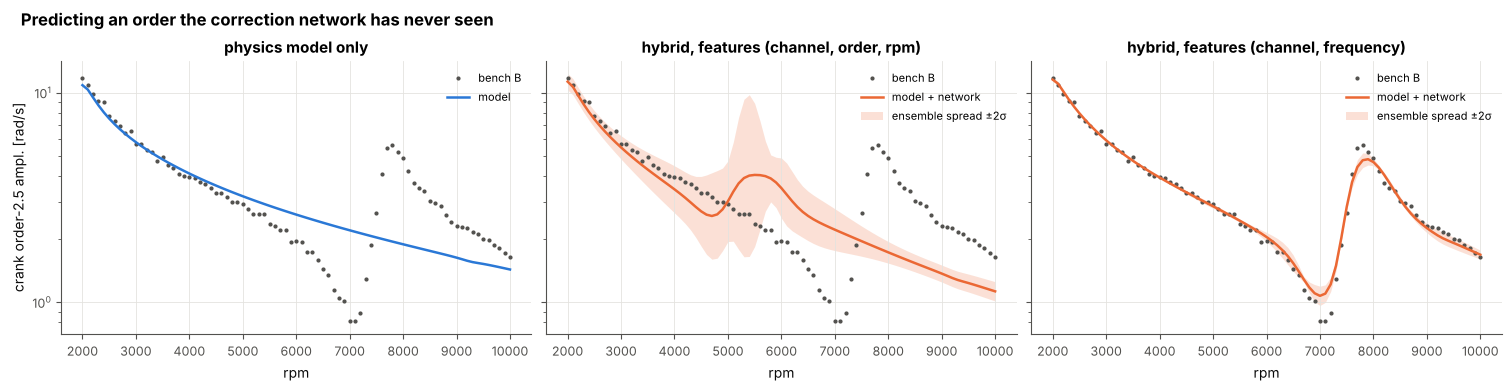

In [9]:
i25 = list(dl.ORDERS).index(2.5)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
base_amp = dl.simulate(xB)
for a, (title, key) in zip(axes, (("physics model only", None),
                                  ("hybrid, features (channel, order, rpm)", "(channel, order, rpm)"),
                                  ("hybrid, features (channel, frequency)", "(channel, frequency)"))):
    a.semilogy(dl.RPM, bench_B["amp"][0, i25], ".", color=plotstyle.MUTED, ms=4, label="bench B")
    if key is None:
        a.semilogy(dl.RPM, base_amp[0, i25], color=C[0], label="model")
    else:
        mu_h, sd_h = (v.reshape(shape)[0, i25] for v in results[key][2:])
        pred = np.log(base_amp[0, i25] + 0.05) + mu_h
        a.semilogy(dl.RPM, np.exp(pred), color=C[1], label="model + network")
        a.fill_between(dl.RPM, np.exp(pred - 2 * sd_h), np.exp(pred + 2 * sd_h), color=C[1], alpha=0.2, lw=0,
                       label="ensemble spread ±2σ")
    a.set(title=title, xlabel="rpm")
    a.legend(fontsize=8)
axes[0].set_ylabel("crank order-2.5 ampl. [rad/s]")
fig.suptitle("Predicting an order the correction network has never seen", x=0.01, ha="left", fontweight="bold")
plt.show()

Three results, in increasing order of importance:

1. **The hybrid model fits.** On the calibration run both feature choices bring
   the error from about 0.19 down to 0.05–0.06, close to the noise level.
2. **It transfers to the other load case** (0.18 → about 0.06) – with either
   feature set. There is a physical reason: for a linear system the *ratio*
   between real and modelled response is a property of the transfer path and
   does not depend on how hard the engine excites it.
3. **Only the frequency-based network predicts an unseen order.** With
   (channel, order, rpm) inputs the network has no idea what order 2.5 does – its
   correction there is worse than no correction. With frequency as input it has
   already seen the 310 Hz region through order 3 and transfers that knowledge.
   Same data, same network, same training; the only difference is one line of
   physics in the feature definition.

That third point is the main message of this notebook. **In engineering ML the
leverage is rarely in the network architecture. It is in how much physical
structure you build in:** which model carries the bulk, what the network is asked
to correct, and in which coordinates.

The limits remain those of notebook 03. The hybrid model predicts the bench
better, but the physical parameters underneath are still the biased ones; a
design study (notebook 05) based on them inherits the bias. And the correction
is only trustworthy where it was trained – other frequencies, a different
gearbox or a different temperature are extrapolation. The ensemble spread gives
a hint (it widens where the members disagree) but it is not a guarantee.

## 4 · Where to go from here

* **Differentiable physics.** Instead of approximating the model with a
  network, write the model itself in PyTorch or JAX. The frequency-domain solve
  of `dl.simulate` is a few lines of `torch.linalg.solve`; automatic
  differentiation then gives exact Jacobians for least squares (no finite
  differences, no step-size question) and lets you train a correction network
  *inside* the physics rather than on top of it. For models you write yourself
  in Python this is often the most valuable step.
* **Time-domain surrogates.** For the nonlinear model of notebook 04, KPIs
  discard the dynamics. Sequence models (NARX networks, recurrent or
  convolutional nets) and neural ODEs learn the time behaviour itself; judge
  them by free-run simulation, never by one-step prediction (see the project guide).
* **Uncertainty.** Ensembles (as above), or Gaussian processes on a network's
  learned features, when decisions depend on knowing what the model does not know.
* **Physics-informed networks (PINNs)** solve differential equations with a
  network. For lumped-parameter drivelines you already have fast solvers; PINNs
  are rarely the efficient tool here.

## 5 · The series on one page

| Step | Default tool | Reach for ML when … |
|---|---|---|
| Understand the model | curves, 1-D/2-D sweeps, Sobol/LHS sampling | – |
| Rank parameters, plan tests | local sensitivities, Fisher information, Morris, Sobol | the model is too slow for Sobol → GP surrogate |
| Calibrate | least squares on residual vectors, multi-start, priors | only scalar KPIs → Bayesian optimisation; many calibrations → NN surrogate |
| Trust the result | residual analysis, covariance, profile likelihood, validation | structured residuals with no physical fix → hybrid model |
| Explore designs | constrained optimisation, Pareto fronts, Monte Carlo | expensive model → GP + adaptive sampling; curves/fields → NN surrogate |

### Try it yourself

1. Train the curve surrogate on a narrower parameter box (±15 % around the
   calibrated values). How many runs are needed now? This is the usual situation
   *after* a first calibration.
2. Replace PCA by direct prediction of all 810 outputs. Better or worse?
3. Give the correction network the load as an additional input and train on both
   B runs. Does anything improve?
4. Rewrite `dl.simulate` in PyTorch (`torch.linalg.solve` handles complex
   matrices) and calibrate data set A with `torch.func.jacrev` or plain Adam.
   Compare the exact Jacobian with the finite-difference one from notebook 02.